<a href="https://colab.research.google.com/github/jpsalap/cardiac-acoustic-classification/blob/main/Heart_sounds_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import librosa
import numpy as np

# Define a function to extract MFCCs for a single audio file
def extract_mfcc(audio_file, n_mfcc=14):
    # Load the audio file
    y, sr = librosa.load(audio_file)

    # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    return mfccs

# Define a function to process all audio files in a folder and create a matrix
def process_folder(folder_path):
    # Get a list of all files in the specified directory
    files = [file for file in os.listdir(folder_path) if file.endswith(('.wav', '.mp3'))]

    # Initialize an empty matrix to store the MFCCs for each audio
    mfcc_matrix = np.zeros((len(files), 14))

    # Process each audio file in the folder
    for i, audio_file in enumerate(files):
        audio_file_path = os.path.join(folder_path, audio_file)
        mfccs = extract_mfcc(audio_file_path)

        # Take the mean of the MFCC coefficients to get 14 values
        mfcc_mean = np.mean(mfccs, axis=1)
        mfcc_matrix[i, :] = mfcc_mean

    return mfcc_matrix

# Example folder containing audio files
folder_path = "/content/drive/MyDrive/University/Semester 10/Optative 3/Michigan_Heart_Sounds/Normal/01 Apex, Normal S1 S2, Supine, Bell/Split files 01"

# Process the folder and create the MFCC matrix
mfcc_matrix = process_folder(folder_path)

# The mfcc_matrix now contains 14 coefficients per audio file in the folder
print("MFCC Matrix:")
print(mfcc_matrix)



MFCC Matrix:
[[-477.54748535   28.71339417   27.21582031 ...    4.56214714
     3.64541149    3.00541329]
 [-471.89663696   30.79523659   29.18779755 ...    4.80906296
     3.93550992    3.37825656]
 [-470.71466064   32.92053223   30.97624016 ...    4.4923687
     3.59222484    2.95631361]
 ...
 [-467.33508301   30.51652336   29.00283623 ...    4.82061243
     3.87750864    3.29079771]
 [-470.26373291   29.6470623    27.82783508 ...    5.02912855
     4.36493158    3.87610698]
 [-472.51278687   28.26527214   26.74161911 ...    4.69126797
     3.8810041     3.33868098]]


KNN

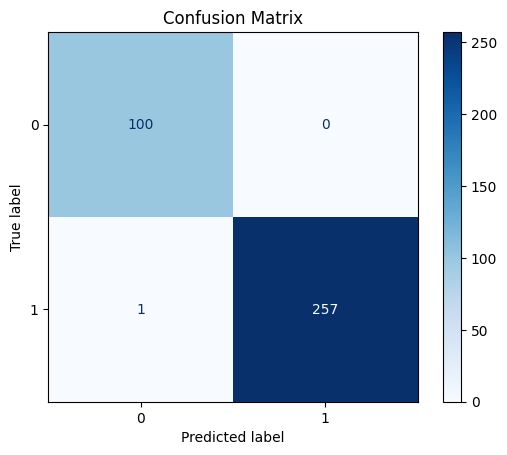

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       100
           1       1.00      1.00      1.00       258

    accuracy                           1.00       358
   macro avg       1.00      1.00      1.00       358
weighted avg       1.00      1.00      1.00       358

KNN Classification Results:
Accuracy: 99.72%
Confusion Matrix:
[[100   0]
 [  1 257]]
Precision: 1.0000
Recall (Sensitivity): 0.9961
F1 Score: 0.9981


In [ ]:
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from librosa.util import normalize

# Define a function to extract normalized MFCCs for a single audio file
def extract_normalized_mfcc(audio_file, n_mfcc=14):
    # Load the audio file
    y, sr = librosa.load(audio_file)

    # Normalize the audio signal
    y = normalize(y)

    # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    return mfccs

# Define a function to process all audio files in a folder and create a matrix
def process_folder(folder_path):
    # Get a list of all files in the specified directory
    files = [file for file in os.listdir(folder_path) if file.endswith(('.wav', '.mp3'))]

    # Initialize lists to store normalized MFCCs and labels
    mfcc_list = []
    labels = []

    # Process each audio file in the folder
    for i, audio_file in enumerate(files):
        audio_file_path = os.path.join(folder_path, audio_file)
        mfccs = extract_normalized_mfcc(audio_file_path)

        # Take the mean of the normalized MFCC coefficients to get 14 values
        mfcc_mean = np.mean(mfccs, axis=1)
        mfcc_list.append(mfcc_mean)

        # Extract label from the file name (assuming 'normal' or 'abnormal' in the file name)
        label = 1 if 'abnormal' in audio_file.lower() else 0
        labels.append(label)

    # Check if there's only one class in the dataset
    unique_labels = np.unique(labels)
    if len(unique_labels) == 1:
        raise ValueError("Dataset contains only one class. Ensure that 'normal' and 'abnormal' labels are correctly extracted.")

    return np.array(mfcc_list), np.array(labels)

# Example folder containing audio files
folder_path = "/content/drive/MyDrive/University/Semester 10/Optative 3/Dataset/Michigan_Heart_Sounds"

# Process the folder and create the normalized MFCC matrix and labels
X, y = process_folder(folder_path)

# Check if there's only one class in the dataset
unique_labels = np.unique(y)
if len(unique_labels) == 1:
    raise ValueError("Dataset contains only one class. Ensure that 'normal' and 'abnormal' labels are correctly extracted.")

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a KNN model
model = KNeighborsClassifier(n_neighbors=5)

# Train the model on the training data
model.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
confusion = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Display classification report
report = classification_report(y_test, y_pred)
print("Classification Report:")
print(report)

# Extract additional metrics from the confusion matrix
true_negative, false_positive, false_negative, true_positive = confusion.ravel()
precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)
f1_score = 2 * (precision * recall) / (precision + recall)
specificity = true_negative / (true_negative + false_positive)
sensitivity = recall

print("KNN Classification Results:")
print(f"Accuracy: {accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(confusion)
print(f"Precision: {precision:.4f}")
print(f"Recall (Sensitivity): {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")


SVM

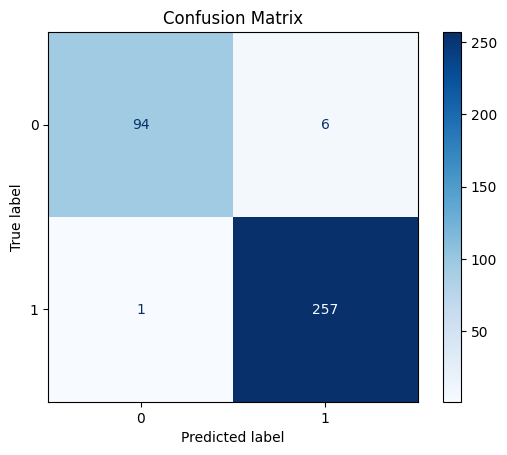

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.96       100
           1       0.98      1.00      0.99       258

    accuracy                           0.98       358
   macro avg       0.98      0.97      0.98       358
weighted avg       0.98      0.98      0.98       358

SVM Classification Results:
Accuracy: 98.04%
Precision: 0.9772
Recall (Sensitivity): 0.9961
F1 Score: 0.9866
Specificity: 0.9400


In [ ]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from librosa.util import normalize

# Define a function to extract normalized MFCCs for a single audio file
def extract_normalized_mfcc(audio_file, n_mfcc=14):
    # Load the audio file
    y, sr = librosa.load(audio_file)

    # Normalize the audio signal
    y = normalize(y)

    # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    return mfccs

# Define a function to process all audio files in a folder and create a matrix
def process_folder(folder_path):
    # Get a list of all files in the specified directory
    files = [file for file in os.listdir(folder_path) if file.endswith(('.wav', '.mp3'))]

    # Initialize lists to store normalized MFCCs and labels
    mfcc_list = []
    labels = []

    # Process each audio file in the folder
    for i, audio_file in enumerate(files):
        audio_file_path = os.path.join(folder_path, audio_file)
        mfccs = extract_normalized_mfcc(audio_file_path)

        # Take the mean of the normalized MFCC coefficients to get 14 values
        mfcc_mean = np.mean(mfccs, axis=1)
        mfcc_list.append(mfcc_mean)

        # Extract label from the file name (assuming 'normal' or 'abnormal' in the file name)
        label = 1 if 'abnormal' in audio_file.lower() else 0
        labels.append(label)

    # Check if there's only one class in the dataset
    unique_labels = np.unique(labels)
    if len(unique_labels) == 1:
        raise ValueError("Dataset contains only one class. Ensure that 'normal' and 'abnormal' labels are correctly extracted.")

    return np.array(mfcc_list), np.array(labels)

# Example folder containing audio files
folder_path = "/content/drive/MyDrive/University/Semester 10/Optative 3/Dataset/Michigan_Heart_Sounds"

# Process the folder and create the normalized MFCC matrix and labels
X, y = process_folder(folder_path)

# Check if there's only one class in the dataset
unique_labels = np.unique(y)
if len(unique_labels) == 1:
    raise ValueError("Dataset contains only one class. Ensure that 'normal' and 'abnormal' labels are correctly extracted.")

# Use only the first two MFCCs for visualization
X_visualize = X[:, :2]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create an SVC model
model = SVC(kernel='linear', C=1.0)

# Train the model on the training data
model.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
confusion = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Display classification report
report = classification_report(y_test, y_pred)
print("Classification Report:")
print(report)

# Extract additional metrics from the confusion matrix
true_negative, false_positive, false_negative, true_positive = confusion.ravel()
precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)
f1_score = 2 * (precision * recall) / (precision + recall)
specificity = true_negative / (true_negative + false_positive)
sensitivity = recall

print("SVM Classification Results:")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall (Sensitivity): {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")
print(f"Specificity: {specificity:.4f}")

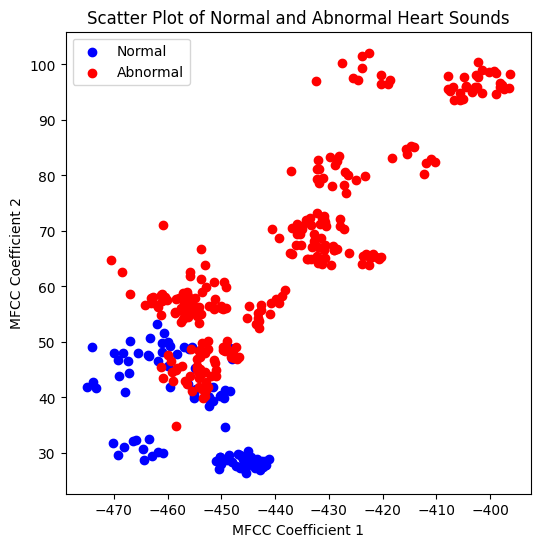

In [ ]:
# Scatter plot of data points
plt.figure(figsize=(6, 6))

# Plot data points for normal heart sounds
normal_indices = np.where(y_test == 0)[0]
plt.scatter(X_test[normal_indices, 0], X_test[normal_indices, 1], c='blue', label='Normal')

# Plot data points for abnormal heart sounds
abnormal_indices = np.where(y_test == 1)[0]
plt.scatter(X_test[abnormal_indices, 0], X_test[abnormal_indices, 1], c='red', label='Abnormal')

# Add labels and title
plt.xlabel('MFCC Coefficient 1')
plt.ylabel('MFCC Coefficient 2')
plt.title('Scatter Plot of Normal and Abnormal Heart Sounds')
plt.legend()
plt.show()